In [34]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

t = sp.symbols("t")
x = sp.Function("x")
y = sp.Function("y")
alpha, beta, gamma, delta = (2, 4, 1, 3)


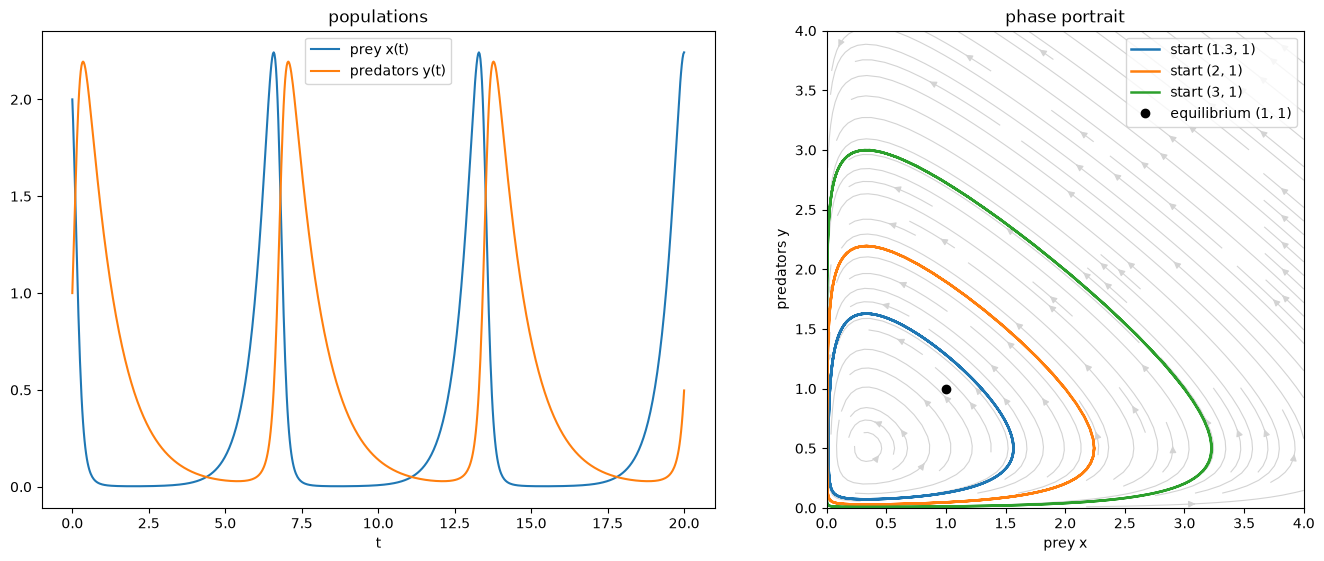

In [35]:
def LV(t, u):
    x, y = u
    return [alpha * x - beta * x * y, delta * x * y - gamma * y]

tt = np.linspace(0, 20, 800)
sol = solve_ivp(LV, (0, 20), [2, 1], t_eval=tt, rtol=1e-9, atol=1e-12)

xs = np.linspace(0.01, 4, 21)
Xg, Yg = np.meshgrid(xs, xs)
U, V = LV(0, [Xg, Yg])

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
axs[0].plot(tt, sol.y[0], label="prey x(t)")
axs[0].plot(tt, sol.y[1], label="predators y(t)")
axs[0].set_xlabel("t"); axs[0].legend(); axs[0].set_title("populations")

axs[1].streamplot(Xg, Yg, U, V, color="lightgray", density=1.2, linewidth=0.8)
for x0 in [1.3, 2, 3]:
    s = solve_ivp(LV, (0, 20), [x0, 1], t_eval=tt, rtol=1e-9, atol=1e-12)
    axs[1].plot(s.y[0], s.y[1], lw=1.8, label=f"start ({x0}, 1)")
axs[1].plot(1, 1, "o", color="k", label="equilibrium (1, 1)")
axs[1].set_xlim(0, 4); axs[1].set_ylim(0, 4); axs[1].set_aspect("equal")
axs[1].set_xlabel("prey x"); axs[1].set_ylabel("predators y"); axs[1].legend(loc="upper right")
axs[1].set_title("phase portrait")
plt.show()